In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [ ]:
sales = pd.read_csv("train.csv")
games = pd.read_csv("vgsales.csv")

In [ ]:
sales.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [ ]:
games.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:
print("Sales Dataset Shape:", sales.shape)
print("Video Game Dataset Shape:", games.shape)

Sales Dataset Shape: (9800, 18)
Video Game Dataset Shape: (16598, 11)


In [ ]:
sales.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='object')

In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [ ]:
sales.isnull().sum()


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [ ]:
sales.duplicated().sum()

np.int64(0)

In [ ]:
sales = sales.drop_duplicates()

In [ ]:
sales.duplicated().sum()

np.int64(0)

In [ ]:
sales["Order Date"] = pd.to_datetime(
    sales["Order Date"],
    dayfirst=True
)

sales["Ship Date"] = pd.to_datetime(
    sales["Ship Date"],
    dayfirst=True
)

In [ ]:
sales["Order Date"].head()

,Order Date
0,2017-11-08
1,2017-11-08
2,2017-06-12
3,2016-10-11
4,2016-10-11


In [ ]:
sales["Ship Date"].head()

,Ship Date
0,2017-11-11
1,2017-11-11
2,2017-06-16
3,2016-10-18
4,2016-10-18


In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

In [ ]:
sales["Order Date"].head(10)

,Order Date
0,2017-11-08
1,2017-11-08
2,2017-06-12
3,2016-10-11
4,2016-10-11
5,2015-06-09
6,2015-06-09
7,2015-06-09
8,2015-06-09
9,2015-06-09


In [ ]:
print(sales["Order Date"].head(10))

0   2017-11-08
1   2017-11-08
2   2017-06-12
3   2016-10-11
4   2016-10-11
5   2015-06-09
6   2015-06-09
7   2015-06-09
8   2015-06-09
9   2015-06-09
Name: Order Date, dtype: datetime64[ns]


In [ ]:
print(sales.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

In [ ]:
sales["Order Date"].head(10)

,Order Date
0,2017-11-08
1,2017-11-08
2,2017-06-12
3,2016-10-11
4,2016-10-11
5,2015-06-09
6,2015-06-09
7,2015-06-09
8,2015-06-09
9,2015-06-09


In [ ]:
sales["Order Date"].unique()[:10]

<DatetimeArray>
['2017-11-08 00:00:00', '2017-06-12 00:00:00', '2016-10-11 00:00:00',
 '2015-06-09 00:00:00', '2018-04-15 00:00:00', '2017-12-05 00:00:00',
 '2016-11-22 00:00:00', '2015-11-11 00:00:00', '2015-05-13 00:00:00',
 '2015-08-27 00:00:00']
Length: 10, dtype: datetime64[ns]

In [ ]:
sales["Order Date"] = pd.to_datetime(
    sales["Order Date"],
    dayfirst=True,
    errors="coerce"
)

sales["Ship Date"] = pd.to_datetime(
    sales["Ship Date"],
    dayfirst=True,
    errors="coerce"
)

In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

In [ ]:
print("Order Date missing:", sales["Order Date"].isna().sum())
print("Ship Date missing:", sales["Ship Date"].isna().sum())

Order Date missing: 0
Ship Date missing: 0


In [ ]:
sales["Year"] = sales["Order Date"].dt.year
sales["Month"] = sales["Order Date"].dt.month
sales["Month Name"] = sales["Order Date"].dt.month_name()
sales["Quarter"] = sales["Order Date"].dt.quarter
sales["Week"] = sales["Order Date"].dt.isocalendar().week
sales["Day"] = sales["Order Date"].dt.day_name()

In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

sales["Season"] = sales["Month"].apply(get_season)

In [ ]:
sales.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Year,Month,Month Name,Quarter,Week,Day,Season
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,4,45,Wednesday,Autumn
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,4,45,Wednesday,Autumn
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,2,24,Monday,Summer
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,4,41,Tuesday,Autumn
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,4,41,Tuesday,Autumn


In [ ]:
daily_sales = sales.groupby("Order Date")["Sales"].sum().reset_index()

daily_sales.head()

,Order Date,Sales
0,2015-01-03,16.448
1,2015-01-04,288.060
2,2015-01-05,19.536
3,2015-01-06,4407.100
4,2015-01-07,87.158


In [ ]:
weekly_sales = (
    sales.groupby(pd.Grouper(key="Order Date", freq="W"))["Sales"]
    .sum()
    .reset_index()
)

weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


In [ ]:
monthly_sales = (
    sales.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
    .sum()
    .reset_index()
)

monthly_sales.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [ ]:
category_sales = sales.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


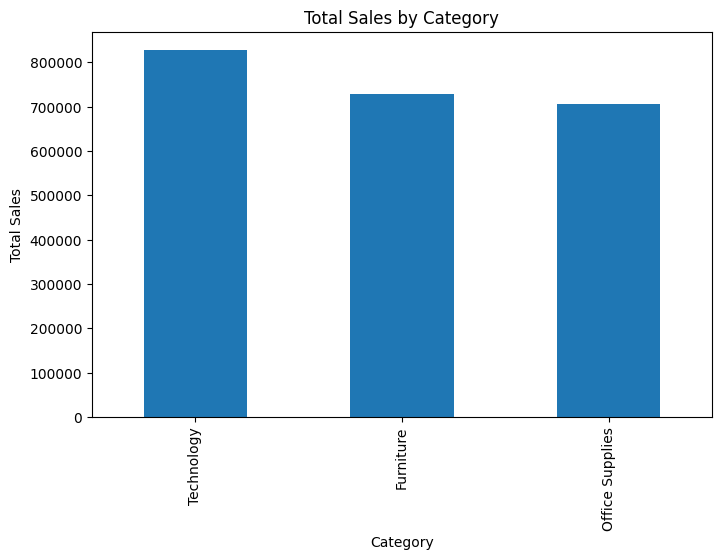

In [ ]:
plt.figure(figsize=(8,5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

In [ ]:
region_sales = sales.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


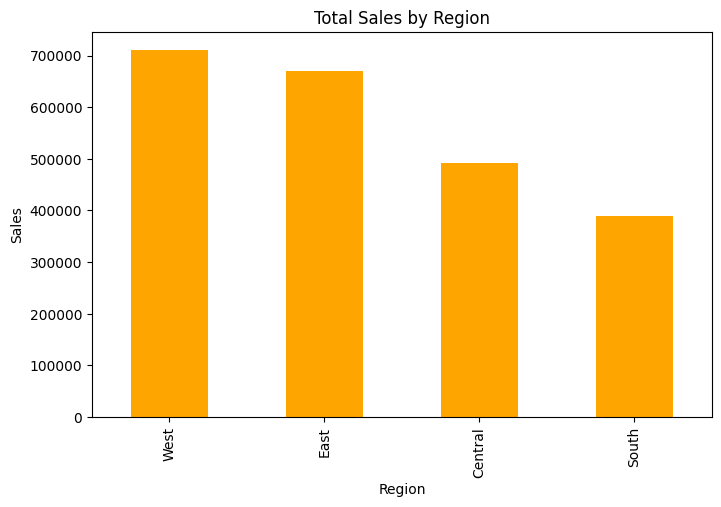

In [ ]:
plt.figure(figsize=(8,5))

region_sales.plot(kind="bar", color="orange")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.show()

In [ ]:
sales["Shipping Days"] = (
    sales["Ship Date"] - sales["Order Date"]
).dt.days

sales["Shipping Days"].head()

,Shipping Days
0,3
1,3
2,4
3,7
4,7


In [ ]:
sales["Shipping Days"].mean()

np.float64(3.9611224489795918)

In [ ]:
shipping_region = (
    sales.groupby("Region")["Shipping Days"]
    .mean()
    .sort_values()
)

print(shipping_region)

Region
East       3.910233
West       3.930255
South      3.961202
Central    4.065876
Name: Shipping Days, dtype: float64


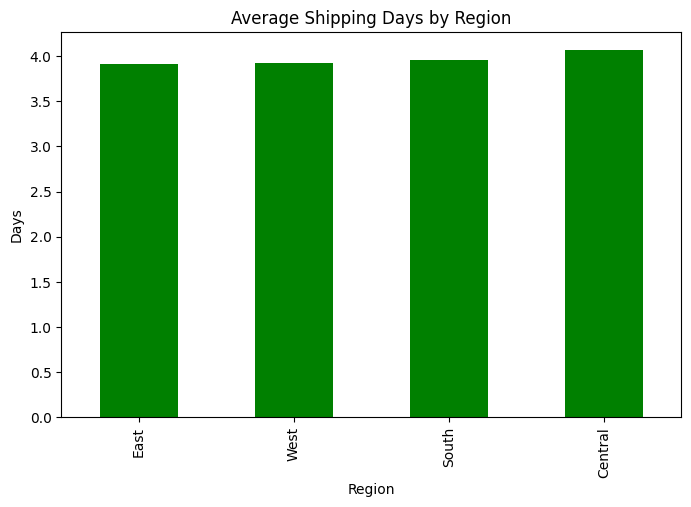

In [ ]:
plt.figure(figsize=(8,5))

shipping_region.plot(kind="bar", color="green")

plt.title("Average Shipping Days by Region")
plt.ylabel("Days")

plt.show()

In [ ]:
monthly_trend = (
    sales.groupby("Month Name")["Sales"]
    .sum()
)

In [ ]:
month_order = [
    "January","February","March","April",
    "May","June","July","August",
    "September","October","November","December"
]

monthly_trend = monthly_trend.reindex(month_order)

monthly_trend

,Sales
Month Name,
January,94291.6296
February,59371.1154
March,197573.5872
April,136283.0006
May,154086.7237
June,145837.5233
July,145535.6890
August,157315.9270
September,300103.4117


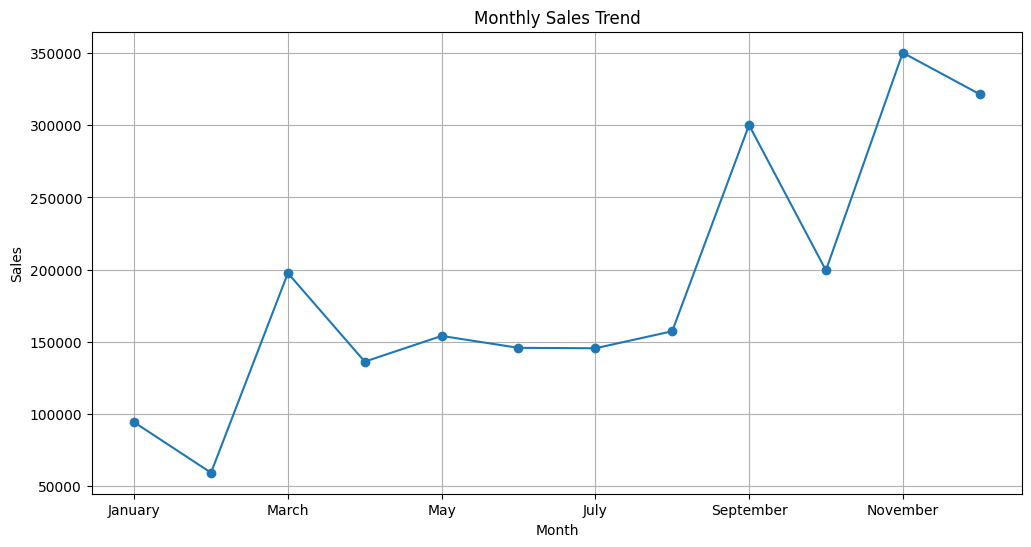

In [ ]:
plt.figure(figsize=(12,6))

monthly_trend.plot(marker="o")

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.grid(True)

plt.show()

In [ ]:
import os

os.makedirs("charts", exist_ok=True)

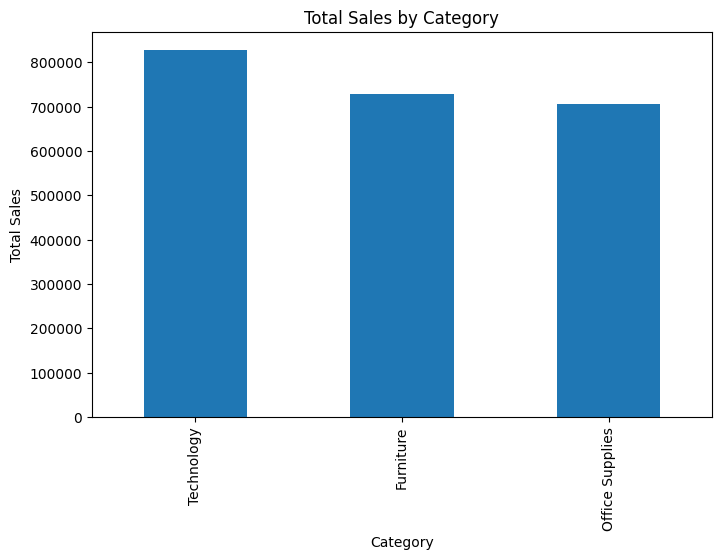

In [ ]:
plt.figure(figsize=(8,5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.savefig("charts/category_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
plt.savefig("charts/region_sales.png", dpi=300, bbox_inches="tight")
plt.savefig("charts/monthly_sales.png", dpi=300, bbox_inches="tight")
plt.savefig("charts/decomposition.png", dpi=300, bbox_inches="tight")
plt.savefig("charts/anomaly_detection.png", dpi=300, bbox_inches="tight")
plt.savefig("charts/clusters.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

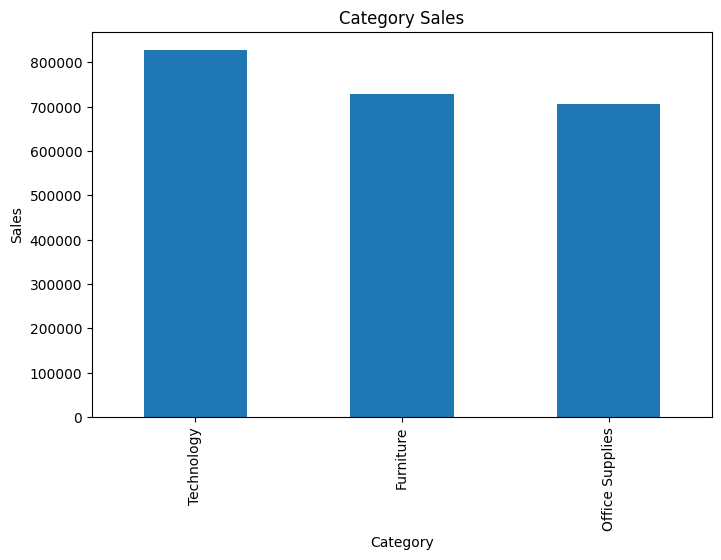

In [ ]:
plt.figure(figsize=(8,5))

category_sales.plot(kind="bar")

plt.title("Category Sales")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.savefig("charts/category_sales.png", dpi=300, bbox_inches="tight")

plt.show()

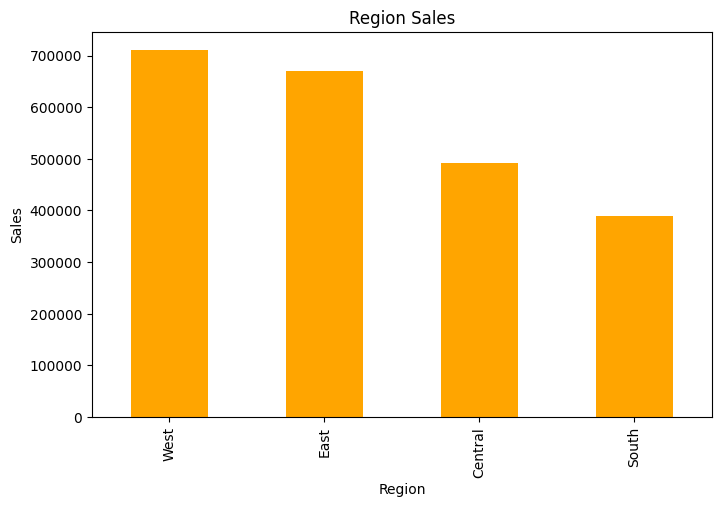

In [ ]:
plt.figure(figsize=(8,5))

region_sales.plot(kind="bar", color="orange")

plt.title("Region Sales")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.savefig("charts/region_sales.png", dpi=300, bbox_inches="tight")

plt.show()

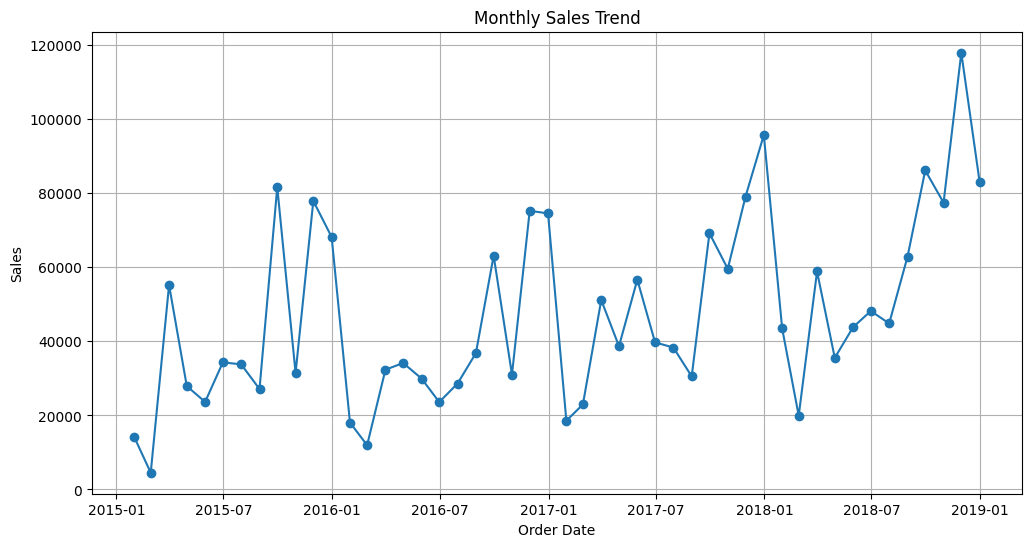

In [ ]:
monthly_sales = (
    sales.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.grid(True)

plt.savefig("charts/monthly_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
region_yearly = sales.groupby(["Year", "Region"])["Sales"].sum().reset_index()

region_yearly.head()

,Year,Region,Sales
0,2015,Central,102920.5206
1,2015,East,127652.8190
2,2015,South,103374.9055
3,2015,West,145907.9630
4,2016,Central,102425.1724


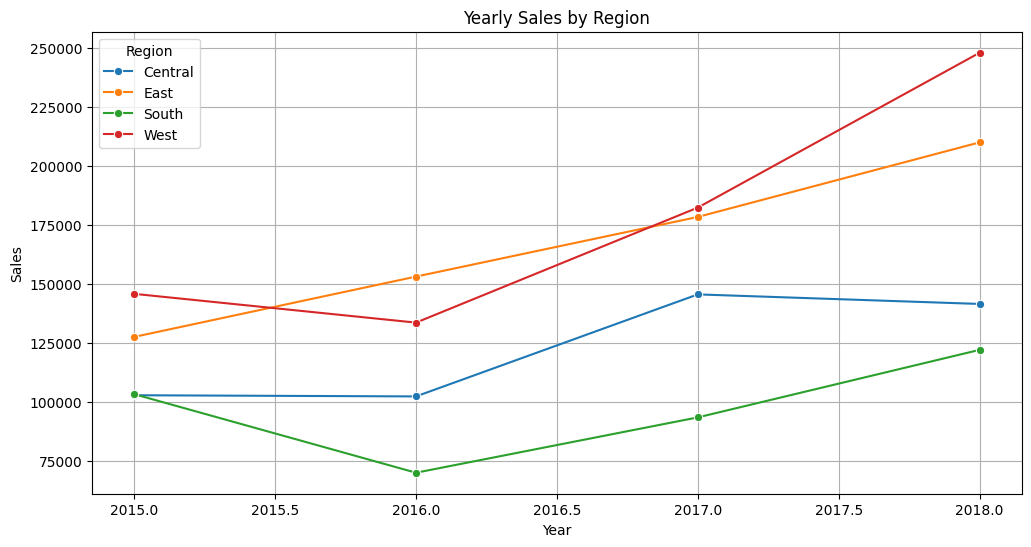

In [ ]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=region_yearly,
    x="Year",
    y="Sales",
    hue="Region",
    marker="o"
)

plt.title("Yearly Sales by Region")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.grid(True)

plt.savefig("charts/yearly_region_sales.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
sales["Shipping Days"] = (
    sales["Ship Date"] - sales["Order Date"]
).dt.days

sales["Shipping Days"].head()

,Shipping Days
0,3
1,3
2,4
3,7
4,7


In [ ]:
average_shipping = sales["Shipping Days"].mean()

print("Average Shipping Time:", average_shipping)

Average Shipping Time: 3.9611224489795918


In [ ]:
shipping_region = (
    sales.groupby("Region")["Shipping Days"]
    .mean()
    .sort_values()
)

print(shipping_region)

Region
East       3.910233
West       3.930255
South      3.961202
Central    4.065876
Name: Shipping Days, dtype: float64


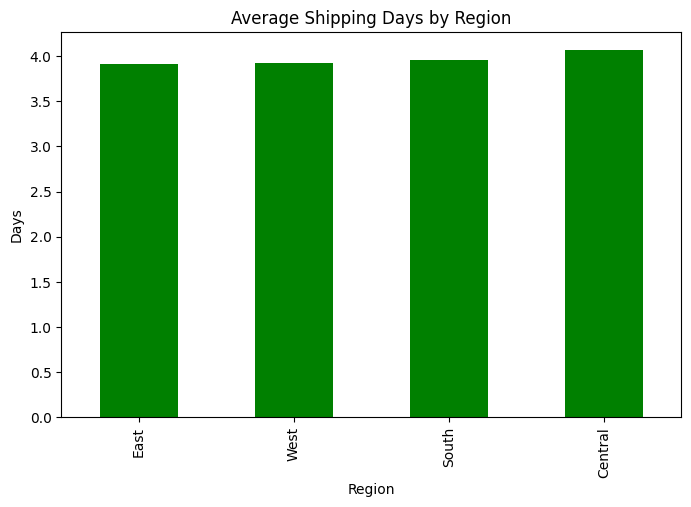

In [ ]:
plt.figure(figsize=(8,5))

shipping_region.plot(kind="bar", color="green")

plt.title("Average Shipping Days by Region")
plt.xlabel("Region")
plt.ylabel("Days")

plt.savefig("charts/shipping_days_region.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
monthly_year = sales.groupby(
    ["Year", "Month"]
)["Sales"].sum().reset_index()

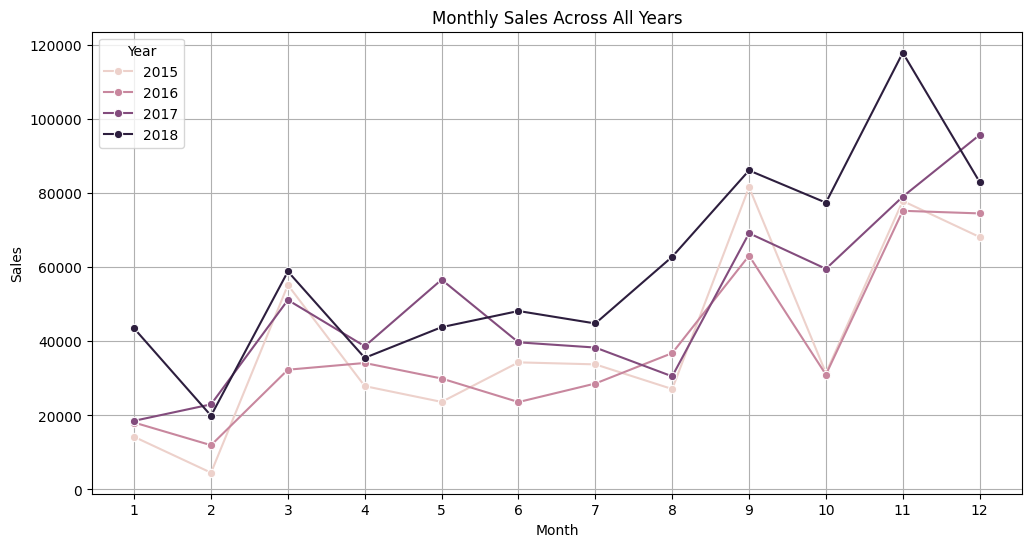

In [ ]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_year,
    x="Month",
    y="Sales",
    hue="Year",
    marker="o"
)

plt.title("Monthly Sales Across All Years")

plt.xticks(range(1,13))

plt.grid(True)

plt.savefig("charts/monthly_sales_all_years.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
sales.to_csv("cleaned_sales.csv", index=False)

Task 2: Time Series Analysis & Decomposition

In [ ]:
import sys
!{sys.executable} -m pip install statsmodels

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

In [ ]:
monthly_series = monthly_sales.copy()

monthly_series.set_index("Order Date", inplace=True)

monthly_series.head()

,Sales
Order Date,
2015-01-31,14205.707
2015-02-28,4519.892
2015-03-31,55205.797
2015-04-30,27906.855
2015-05-31,23644.303


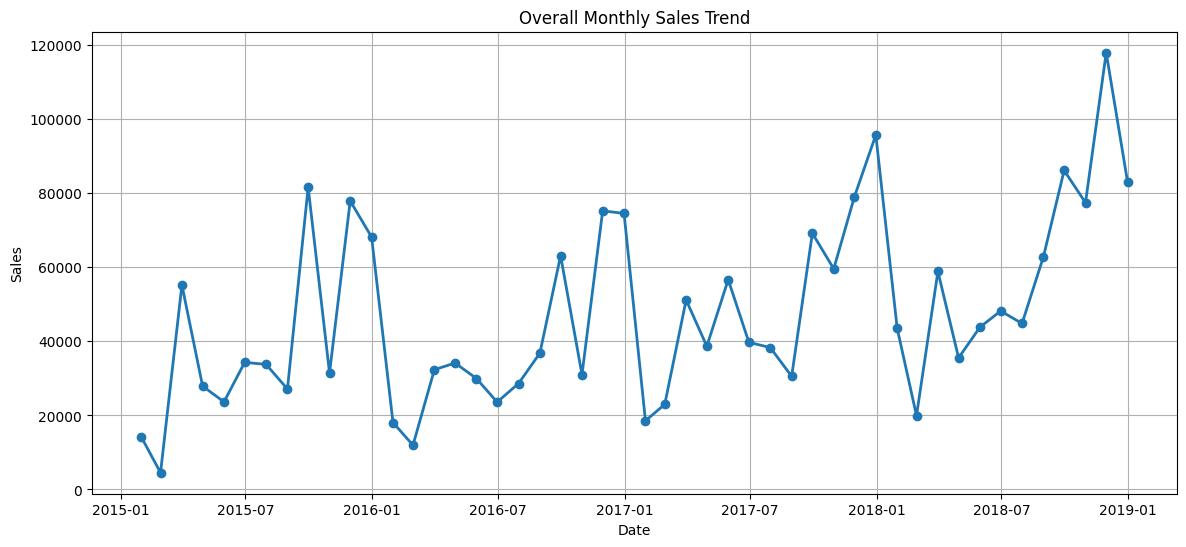

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_series.index,
    monthly_series["Sales"],
    marker="o",
    linewidth=2
)

plt.title("Overall Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

plt.savefig(
    "charts/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
decomposition = seasonal_decompose(
    monthly_series["Sales"],
    model="additive",
    period=12
)

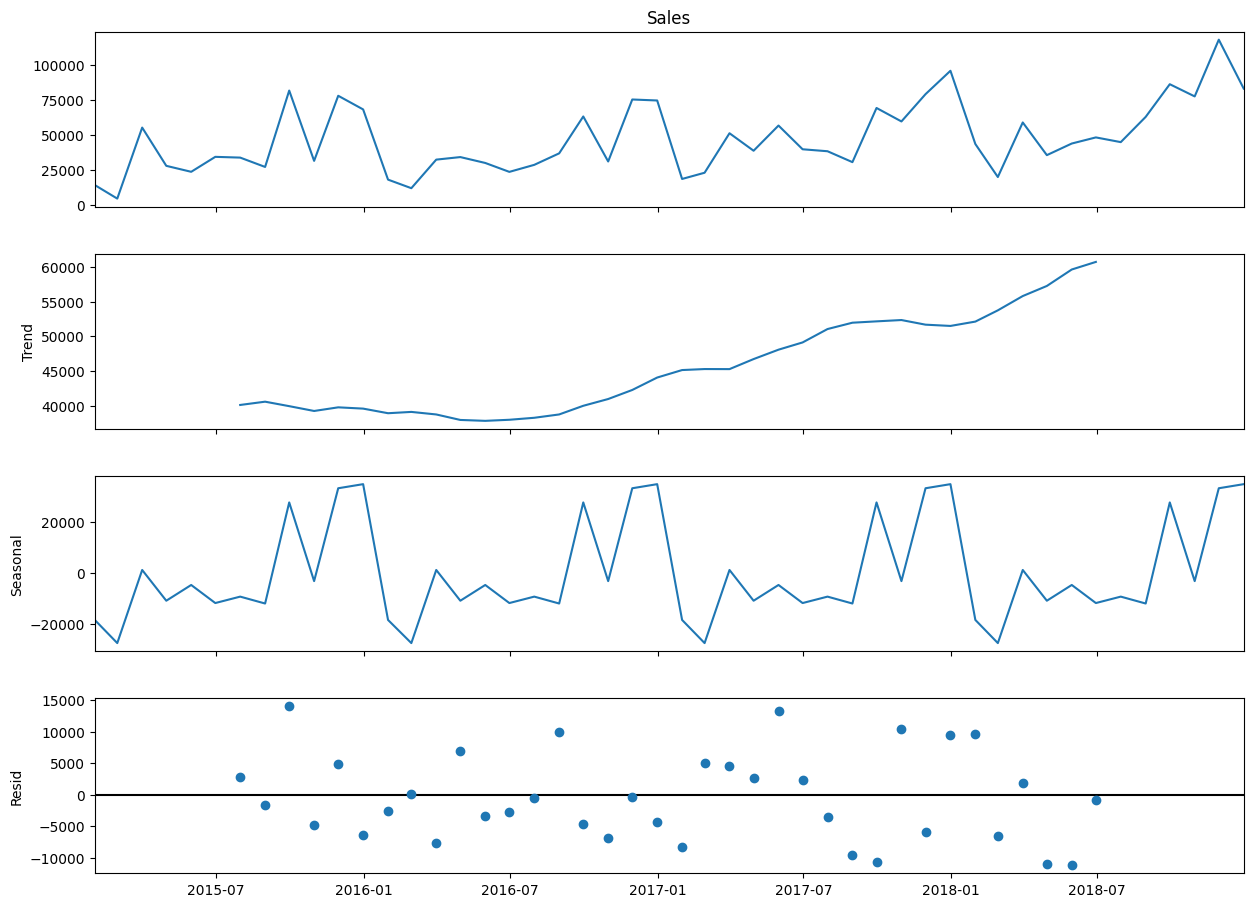

In [ ]:
fig = decomposition.plot()

fig.set_size_inches(14,10)

plt.savefig(
    "charts/decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Time Series Decomposition Observations

1. The trend component shows the long-term direction of sales over time.
2. The seasonal component indicates recurring monthly sales patterns.
3. The residual component captures irregular fluctuations not explained by trend or seasonality.
4. The observed series combines all three components.

In [ ]:
result = adfuller(monthly_series["Sales"])

print("ADF Statistic :", result[0])
print("p-value       :", result[1])
print("Critical Values:")

for key, value in result[4].items():
    print(f"{key}: {value}")

ADF Statistic : -4.416136761430769
p-value       : 0.00027791039276670623
Critical Values:
1%: -3.5778480370438146
5%: -2.925338105429433
10%: -2.6007735310095064


In [ ]:
monthly_series["Sales_diff"] = monthly_series["Sales"].diff()

monthly_series.head()

,Sales,Sales_diff
Order Date,,
2015-01-31,14205.707,NaN
2015-02-28,4519.892,-9685.815
2015-03-31,55205.797,50685.905
2015-04-30,27906.855,-27298.942
2015-05-31,23644.303,-4262.552


In [ ]:
monthly_series_diff = monthly_series["Sales_diff"].dropna()

In [ ]:
result_diff = adfuller(monthly_series_diff)

print("ADF Statistic :", result_diff[0])
print("p-value       :", result_diff[1])

print("Critical Values:")

for key, value in result_diff[4].items():
    print(f"{key}: {value}")

ADF Statistic : -8.727061830353268
p-value       : 3.2669175472796045e-14
Critical Values:
1%: -3.626651907578875
5%: -2.9459512825788754
10%: -2.6116707716049383


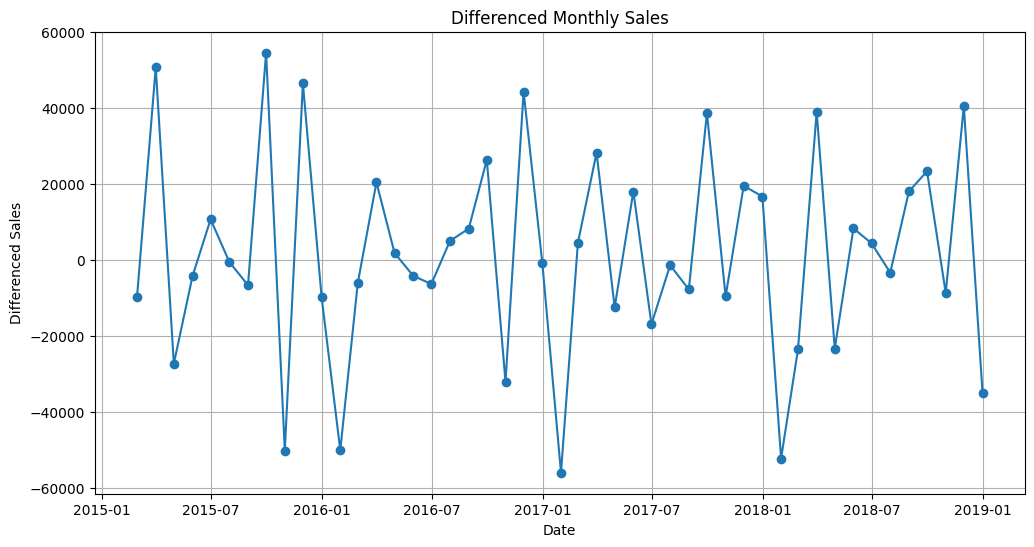

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_series_diff,
    marker="o"
)

plt.title("Differenced Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Differenced Sales")

plt.grid(True)

plt.savefig(
    "charts/differenced_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## ADF Test Results

The Augmented Dickey-Fuller (ADF) test was performed to check whether the monthly sales series was stationary.

### Before Differencing
The original sales series showed a trend and was considered non-stationary.

### After Differencing
After applying first-order differencing, the ADF test produced:

- ADF Statistic: **-8.7271**
- p-value: **3.2669e-14**

Since the p-value is much smaller than 0.05, the null hypothesis is rejected. This confirms that the differenced time series is stationary and suitable for forecasting models such as SARIMA.

Task 3: Sales Forecasting using SARIMA

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

import numpy as np

In [ ]:
train = monthly_series["Sales"][:-3]
test = monthly_series["Sales"][-3:]

print("Training Data:", len(train))
print("Testing Data:", len(test))

Training Data: 45
Testing Data: 3


In [ ]:
sarima_model = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_fit = sarima_model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [ ]:
print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   45
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -347.979
Date:                            Wed, 08 Jul 2026   AIC                            705.958
Time:                                    11:22:41   BIC                            713.287
Sample:                                01-31-2015   HQIC                           708.387
                                     - 09-30-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5680      0.242      2.347      0.019       0.094       1.042
ma.L1         -0.8985      0.177   

In [ ]:
forecast = sarima_fit.forecast(steps=3)

forecast

,predicted_mean
2018-10-31,66177.602425
2018-11-30,92049.249682
2018-12-31,99965.168723


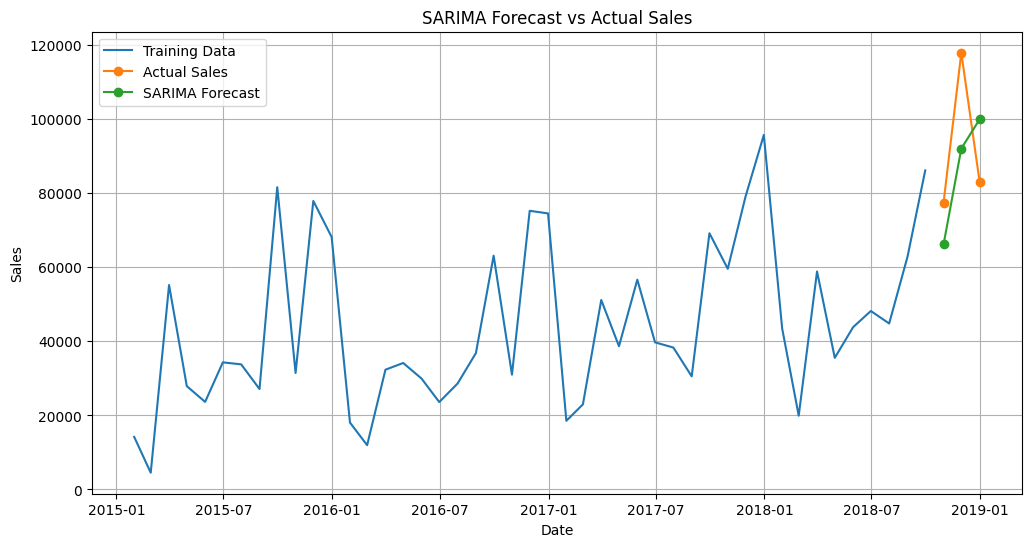

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    test.index,
    forecast,
    label="SARIMA Forecast",
    marker="o"
)

plt.title("SARIMA Forecast vs Actual Sales")

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.savefig(
    "charts/sarima_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(
    mean_squared_error(test, forecast)
)

mape = mean_absolute_percentage_error(
    test,
    forecast
)

print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape)

MAE : 18031.40467222437
RMSE: 19009.18206635205
MAPE: 0.18966498068433016


In [ ]:
sarima_results = pd.DataFrame({
    "Model": ["SARIMA"],
    "MAE": [mae],
    "RMSE": [rmse],
    "MAPE": [mape]
})

sarima_results

,Model,MAE,RMSE,MAPE
0,SARIMA,18031.404672,19009.182066,0.189665


## SARIMA Model Results

The SARIMA model was trained using the monthly sales data with parameters:

- Order: (1,1,1)
- Seasonal Order: (1,1,1,12)

The model was evaluated using the last three months of data.

### Evaluation Metrics

- MAE: 18031.40
- RMSE: 19009.18
- MAPE: 18.97%

The forecast follows the general sales trend and provides a reasonable baseline for comparison with Prophet and XGBoost.

In [ ]:
import sys
!{sys.executable} -m pip install prophet

In [ ]:
from prophet import Prophet

print("Prophet installed successfully!")

Prophet installed successfully!


In [ ]:
from prophet import Prophet
print("Prophet installed successfully!")

Prophet installed successfully!


In [ ]:
from prophet import Prophet

In [ ]:
prophet_data = monthly_sales.rename(
    columns={
        "Order Date": "ds",
        "Sales": "y"
    }
)

prophet_data.head()

,ds,y
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [ ]:
train_prophet = prophet_data[:-3]
test_prophet = prophet_data[-3:]

In [ ]:
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

In [ ]:
prophet_model.fit(train_prophet)

In [ ]:
future = prophet_model.make_future_dataframe(
    periods=3,
    freq="ME"
)

In [ ]:
forecast = prophet_model.predict(future)

forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2015-01-31,33308.214631,6148.022646,22628.874776,33308.214631,33308.214631,-18874.429670,-18874.429670,-18874.429670,-18874.429670,-18874.429670,-18874.429670,0.0,0.0,0.0,14433.784960
1,2015-02-28,33767.643626,-5421.248366,10502.125024,33767.643626,33767.643626,-30869.543104,-30869.543104,-30869.543104,-30869.543104,-30869.543104,-30869.543104,0.0,0.0,0.0,2898.100522
2,2015-03-31,34276.297156,44286.505616,60257.686906,34276.297156,34276.297156,17890.437293,17890.437293,17890.437293,17890.437293,17890.437293,17890.437293,0.0,0.0,0.0,52166.734450
3,2015-04-30,34768.542508,12831.407726,30023.457207,34768.542508,34768.542508,-13661.251247,-13661.251247,-13661.251247,-13661.251247,-13661.251247,-13661.251247,0.0,0.0,0.0,21107.291262
4,2015-05-31,35277.196039,15124.077434,31671.861215,35277.196039,35277.196039,-12398.630441,-12398.630441,-12398.630441,-12398.630441,-12398.630441,-12398.630441,0.0,0.0,0.0,22878.565598


In [ ]:
forecast_values = forecast[["ds", "yhat"]].tail(3)

forecast_values

,ds,yhat
45,2018-10-31,51318.943812
46,2018-11-30,90325.654736
47,2018-12-31,90041.084430


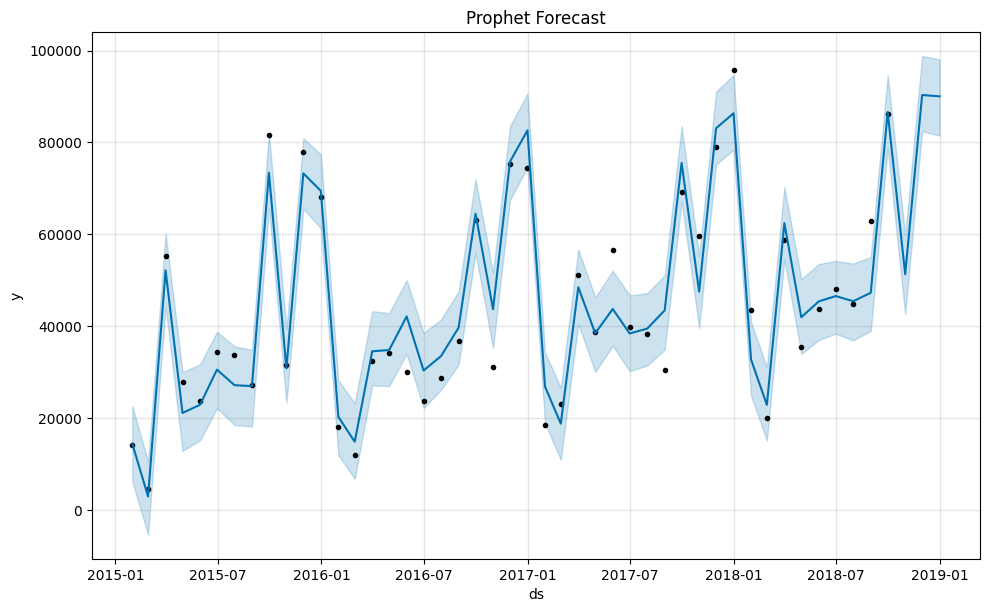

In [ ]:
fig = prophet_model.plot(forecast)

plt.title("Prophet Forecast")

plt.savefig(
    "charts/prophet_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

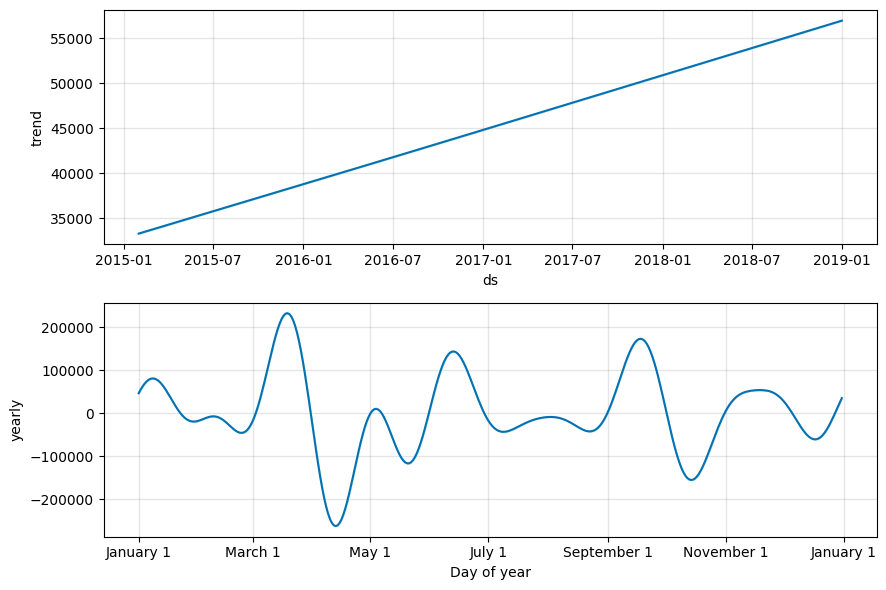

In [ ]:
fig2 = prophet_model.plot_components(forecast)

plt.savefig(
    "charts/prophet_components.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
pred = forecast["yhat"].tail(3).values
actual = test_prophet["y"].values

In [ ]:
mae_prophet = mean_absolute_error(actual, pred)

rmse_prophet = np.sqrt(
    mean_squared_error(actual, pred)
)

mape_prophet = mean_absolute_percentage_error(
    actual,
    pred
)

print("MAE :", mae_prophet)
print("RMSE:", rmse_prophet)
print("MAPE:", mape_prophet)

MAE : 20250.794427610937
RMSE: 22318.41136551923
MAPE: 0.21864628287701435


In [ ]:
prophet_results = pd.DataFrame({
    "Model": ["Prophet"],
    "MAE": [mae_prophet],
    "RMSE": [rmse_prophet],
    "MAPE": [mape_prophet]
})

prophet_results

,Model,MAE,RMSE,MAPE
0,Prophet,20250.794428,22318.411366,0.218646


In [ ]:
!pip install prophet xgboost statsmodels

Task 4 – Category & Region Forecasting

In [ ]:
furniture = sales[sales["Category"] == "Furniture"]
technology = sales[sales["Category"] == "Technology"]
office = sales[sales["Category"] == "Office Supplies"]

west = sales[sales["Region"] == "West"]
east = sales[sales["Region"] == "East"]

In [ ]:
def monthly_data(df):
    monthly = (
        df.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
        .sum()
        .reset_index()
    )
    return monthly

In [ ]:
furniture_monthly = monthly_data(furniture)
technology_monthly = monthly_data(technology)
office_monthly = monthly_data(office)

west_monthly = monthly_data(west)
east_monthly = monthly_data(east)

In [ ]:
print(furniture_monthly.head())
print(technology_monthly.head())
print(office_monthly.head())

  Order Date      Sales
0 2015-01-31   6217.277
1 2015-02-28   1839.658
2 2015-03-31  14243.368
3 2015-04-30   7944.837
4 2015-05-31   6912.787
  Order Date      Sales
0 2015-01-31   3143.290
1 2015-02-28   1608.510
2 2015-03-31  32359.974
3 2015-04-30   8973.144
4 2015-05-31   9599.876
  Order Date      Sales
0 2015-01-31   4845.140
1 2015-02-28   1071.724
2 2015-03-31   8602.455
3 2015-04-30  10988.874
4 2015-05-31   7131.640


In [ ]:
import os

os.makedirs("charts", exist_ok=True)

print("Charts folder created successfully!")

Charts folder created successfully!


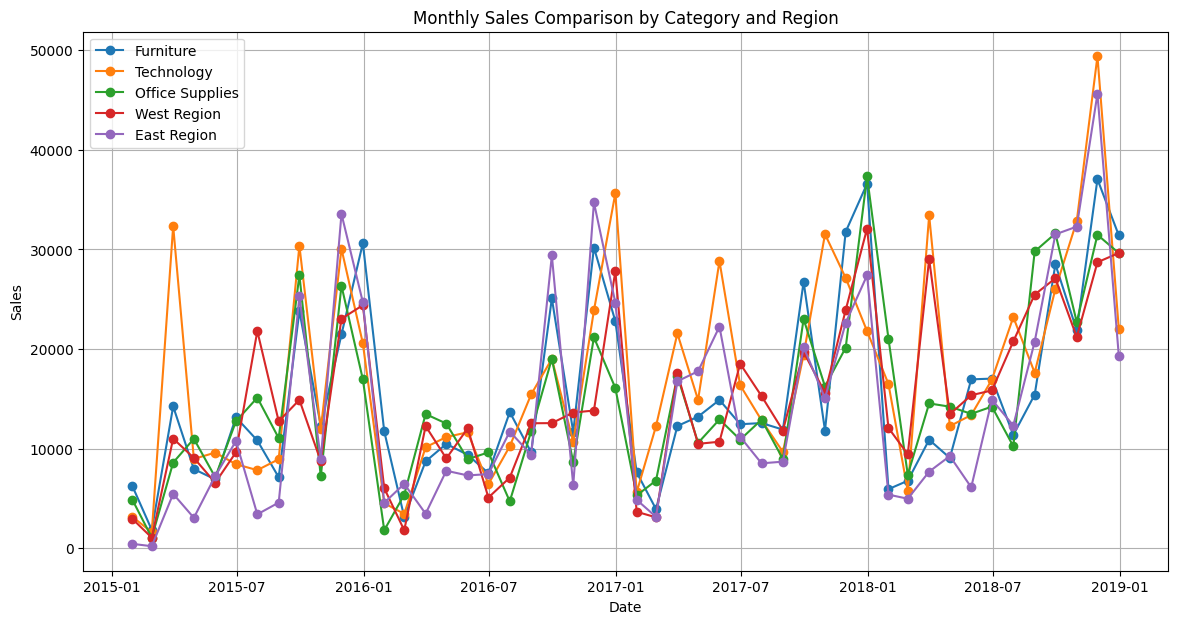

In [ ]:
plt.figure(figsize=(14,7))

plt.plot(
    furniture_monthly["Order Date"],
    furniture_monthly["Sales"],
    marker="o",
    label="Furniture"
)

plt.plot(
    technology_monthly["Order Date"],
    technology_monthly["Sales"],
    marker="o",
    label="Technology"
)

plt.plot(
    office_monthly["Order Date"],
    office_monthly["Sales"],
    marker="o",
    label="Office Supplies"
)

plt.plot(
    west_monthly["Order Date"],
    west_monthly["Sales"],
    marker="o",
    label="West Region"
)

plt.plot(
    east_monthly["Order Date"],
    east_monthly["Sales"],
    marker="o",
    label="East Region"
)

plt.title("Monthly Sales Comparison by Category and Region")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.savefig(
    "charts/category_region_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Task 5 – Anomaly Detection

In [ ]:
from sklearn.ensemble import IsolationForest

In [ ]:
monthly_sales = (
    sales.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
    .sum()
    .reset_index()
)

monthly_sales.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [ ]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

monthly_sales["Anomaly"] = model.fit_predict(
    monthly_sales[["Sales"]]
)

In [ ]:
monthly_sales.head()

,Order Date,Sales,Anomaly
0,2015-01-31,14205.707,1
1,2015-02-28,4519.892,-1
2,2015-03-31,55205.797,1
3,2015-04-30,27906.855,1
4,2015-05-31,23644.303,1


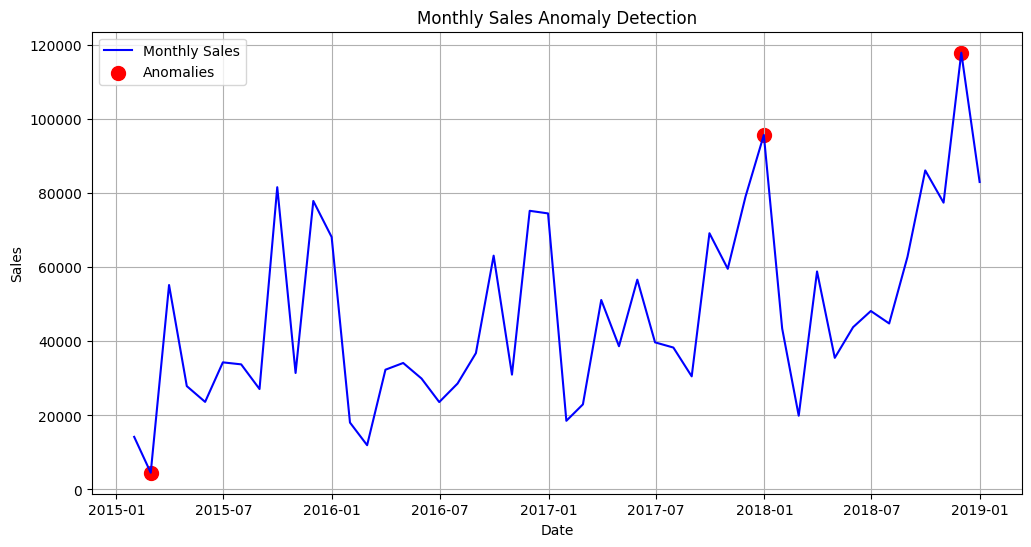

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Monthly Sales",
    color="blue"
)

anomalies = monthly_sales[
    monthly_sales["Anomaly"] == -1
]

plt.scatter(
    anomalies["Order Date"],
    anomalies["Sales"],
    color="red",
    s=100,
    label="Anomalies"
)

plt.title("Monthly Sales Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)

plt.savefig(
    "charts/anomaly_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Anomaly Detection

Isolation Forest was used to identify unusual monthly sales patterns.

### Observations

- Three significant anomalies were detected.
- One anomaly represents an unusually low sales month.
- Two anomalies represent unusually high sales months.
- These anomalies may be associated with seasonal demand, promotional campaigns, or other exceptional business events.

The anomaly detection model helps identify periods that require further business investigation.

Task 6: Customer Segmentation using K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
customer_data = (
    sales.groupby("Customer ID")
    .agg({
        "Sales": "sum",
        "Order ID": "count"
    })
    .reset_index()
)

customer_data.rename(
    columns={"Order ID": "Orders"},
    inplace=True
)

customer_data.head()

,Customer ID,Sales,Orders
0,AA-10315,5563.560,11
1,AA-10375,1056.390,15
2,AA-10480,1790.512,12
3,AA-10645,5086.935,18
4,AB-10015,886.156,6


In [ ]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    customer_data[["Sales", "Orders"]]
)

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(scaled_data)

In [ ]:
customer_data.head()

,Customer ID,Sales,Orders,Cluster
0,AA-10315,5563.560,11,1
1,AA-10375,1056.390,15,1
2,AA-10480,1790.512,12,2
3,AA-10645,5086.935,18,1
4,AB-10015,886.156,6,2


In [1]:
plt.figure(figsize=(10,6))

plt.scatter(
    customer_data["Orders"],
    customer_data["Sales"],
    c=customer_data["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Number of Orders")
plt.ylabel("Total Sales")
plt.title("Customer Segmentation using K-Means")

plt.colorbar(label="Cluster")

plt.savefig(
    "charts/clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'plt' is not defined

In [ ]:
customer_data["Cluster"].value_counts()

,count
Cluster,
2,396
1,324
0,73


In [ ]:
customer_data.groupby("Cluster")[["Sales", "Orders"]].mean()

,Sales,Orders
Cluster,,
0,8902.293997,21.301370
1,3371.703591,15.990741
2,1311.205448,7.737374


## Customer Segmentation

K-Means clustering was applied using two features:

- Total Sales
- Number of Orders

### Cluster Summary

- Cluster 0: High-value customers with high sales and frequent purchases.
- Cluster 1: Medium-value customers with moderate purchasing behavior.
- Cluster 2: Low-value customers with fewer orders and lower total sales.

Customer segmentation can help the business design targeted marketing campaigns and improve customer retention.